In [23]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense as dense,Flatten,MaxPooling2D as maxpooling2d,Conv2D as conv2d,BatchNormalization,Dropout as dd
from tensorflow.keras.utils import load_img, img_to_array
from keras.callbacks import EarlyStopping
import numpy as np
import matplotlib.pyplot as plt

In [24]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("salader/dogsvscats")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'dogsvscats' dataset.
Path to dataset files: /kaggle/input/dogsvscats


In [25]:
train_ds = keras.utils.image_dataset_from_directory(
    directory="/kaggle/input/dogsvscats/train",
    labels="inferred",
    label_mode="int",
    batch_size=32,
    image_size=(256, 256)
)

Found 20000 files belonging to 2 classes.


In [26]:
validation_ds = keras.utils.image_dataset_from_directory(
    directory="/kaggle/input/dogsvscats/test",
    labels="inferred",
    label_mode="int",
    batch_size=32,
    image_size=(256, 256)
)

Found 5000 files belonging to 2 classes.


In [27]:
print(type(train_ds))

<class 'tensorflow.python.data.ops.prefetch_op._PrefetchDataset'>


In [28]:
# x is image
# y is labels 
# train_ds and validation_ds have images with their labels.
train_ds = train_ds.map(lambda x, y: (x / 255.0, y))
valid_ds = validation_ds.map(lambda x, y: (x / 255.0, y))

In [29]:
callback = EarlyStopping( monitor="val_loss",
    min_delta=0,
    patience=0,
    verbose=1,
    mode="auto",
    baseline=None,
    restore_best_weights=False,
    start_from_epoch=0,
)

In [30]:
model = Sequential()
model.add(conv2d(32,kernel_size=(3,3),padding='valid',activation='relu',input_shape=(256,256,3)))
model.add(BatchNormalization())
model.add(maxpooling2d(pool_size=(2,2),strides=2,padding='valid'))
model.add(conv2d(64,kernel_size=(3,3),padding='valid',activation='relu'))
model.add(BatchNormalization())
model.add(maxpooling2d(pool_size=(2,2),strides=2,padding='valid'))
model.add(conv2d(128,kernel_size=(3,3),padding='valid',activation='relu'))
model.add(BatchNormalization())
model.add(maxpooling2d(pool_size=(2,2),strides=2,padding='valid'))


model.add(Flatten())


model.add(dense(128,activation='relu'))
model.add(dd(0.1))
model.add(dense(64,activation='relu'))
model.add(dd(0.1))
model.add(dense(1,activation='sigmoid'))


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [9]:
model = Sequential()
model.add(conv2d(32,kernel_size=(3,3),padding='valid',activation='relu',input_shape=(256,256,3)))

model.add(maxpooling2d(pool_size=(2,2),strides=2,padding='valid'))
model.add(conv2d(64,kernel_size=(3,3),padding='valid',activation='relu'))

model.add(maxpooling2d(pool_size=(2,2),strides=2,padding='valid'))
model.add(conv2d(128,kernel_size=(3,3),padding='valid',activation='relu'))

model.add(maxpooling2d(pool_size=(2,2),strides=2,padding='valid'))


model.add(Flatten())


model.add(dense(128,activation='relu'))

model.add(dense(64,activation='relu'))

model.add(dense(1,activation='sigmoid'))


In [31]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 254, 254, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 125, 125, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 60, 60, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,193 (56.64 MB)

 Trainable params: 14,847,745 (56.64 MB)

 Non-trainable params: 448 (1.75 KB)

In [32]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [ ]:
from tabnanny import verbose


history = model.fit(train_ds,epochs=10,validation_data=valid_ds,verbose=1,callbacks=[callback])

Epoch 1/10
 22/625 ━━━━━━━━━━━━━━━━━━━━ 1:13:49 7s/step - accuracy: 0.5304 - loss: 5.1169

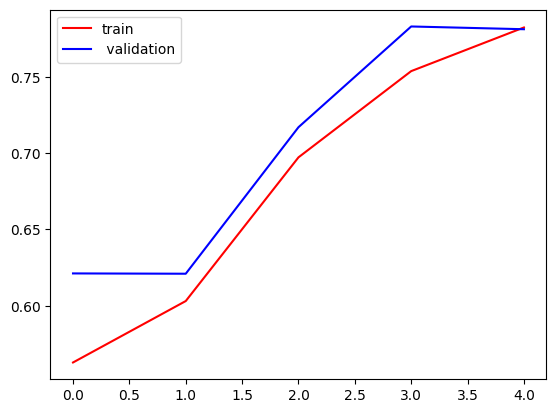

In [ ]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'], color='red', label='train')
plt.plot(history.history['val_accuracy'], color= 'blue', label=' validation')
plt.legend ()
plt.show()

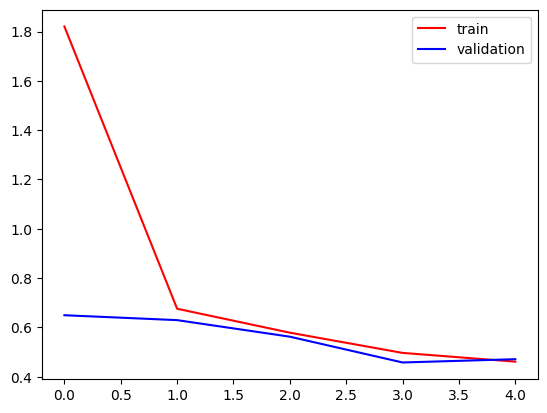

In [26]:
plt.plot(history.history['loss'], color='red', label='train')
plt.plot(history.history['val_loss'], color= 'blue',label='validation')
plt.legend ()
plt.show()


In [1]:
import urllib.request

url = "https://i.pinimg.com/736x/6f/2d/2b/6f2d2b93d70f4b2e2be9b58fd3ffac90.jpg"

urllib.request.urlretrieve(url, "cat.jpg")

('cat.jpg', <http.client.HTTPMessage at 0x7af4beba4890>)

In [4]:
img = load_img("cat.jpg", target_size=(256,256))


In [5]:
import cv2

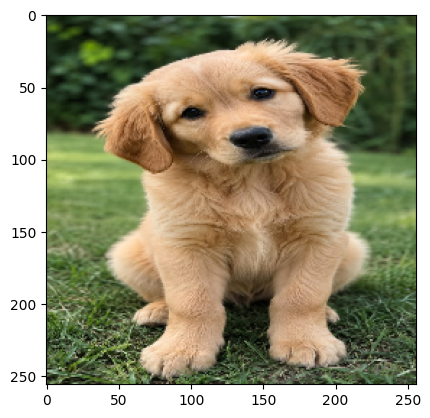

In [8]:
plt.imshow(img)

In [9]:
img_array = img_to_array(img)

print(img_array.shape)

(256, 256, 3)


In [10]:
img_array = img_array / 255.0

In [11]:
img_array = np.expand_dims(img_array, axis=0)

print(img_array.shape)

(1, 256, 256, 3)


In [12]:
prediction = model.predict(img_array)

if prediction>0.5:
    print(f'Dog with {prediction}')
else:
    print(f'cat with {1-prediction}')


NameError: name 'model' is not defined